In [16]:
!pip install -q shap lime xgboost

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

from xgboost import XGBClassifier

print("Libraries imported successfully.")

Libraries imported successfully.


In [18]:
file_path = "/kaggle/input/datasets/mdsolimanarrafi/cicids-2017-merged/CICIDS_2017_Merged.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (2830743, 79)


In [19]:
print("Number of columns:", len(df.columns))

for i, col in enumerate(df.columns):
    print(i, ":", repr(col))

Number of columns: 79
0 : ' Destination Port'
1 : ' Flow Duration'
2 : ' Total Fwd Packets'
3 : ' Total Backward Packets'
4 : 'Total Length of Fwd Packets'
5 : ' Total Length of Bwd Packets'
6 : ' Fwd Packet Length Max'
7 : ' Fwd Packet Length Min'
8 : ' Fwd Packet Length Mean'
9 : ' Fwd Packet Length Std'
10 : 'Bwd Packet Length Max'
11 : ' Bwd Packet Length Min'
12 : ' Bwd Packet Length Mean'
13 : ' Bwd Packet Length Std'
14 : 'Flow Bytes/s'
15 : ' Flow Packets/s'
16 : ' Flow IAT Mean'
17 : ' Flow IAT Std'
18 : ' Flow IAT Max'
19 : ' Flow IAT Min'
20 : 'Fwd IAT Total'
21 : ' Fwd IAT Mean'
22 : ' Fwd IAT Std'
23 : ' Fwd IAT Max'
24 : ' Fwd IAT Min'
25 : 'Bwd IAT Total'
26 : ' Bwd IAT Mean'
27 : ' Bwd IAT Std'
28 : ' Bwd IAT Max'
29 : ' Bwd IAT Min'
30 : 'Fwd PSH Flags'
31 : ' Bwd PSH Flags'
32 : ' Fwd URG Flags'
33 : ' Bwd URG Flags'
34 : ' Fwd Header Length'
35 : ' Bwd Header Length'
36 : 'Fwd Packets/s'
37 : ' Bwd Packets/s'
38 : ' Min Packet Length'
39 : ' Max Packet Length'
40 : '

In [20]:
# Remove leading and trailing spaces from all column names
df.columns = df.columns.str.strip()

print("Column names cleaned successfully.")
print("Number of columns:", len(df.columns))
print(df.columns.tolist())

Column names cleaned successfully.
Number of columns: 79
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Co

In [21]:
print("Label distribution:")
print(df['Label'].value_counts())

print("\nNumber of unique labels:", df['Label'].nunique())
print("\nUnique labels:")
print(df['Label'].unique())

Label distribution:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Number of unique labels: 15

Unique labels:
['BENIGN' 'DDoS' 'PortScan' 'Bot' 'Infiltration'
 'Web Attack � Brute Force' 'Web Attack � XSS'
 'Web Attack � Sql Injection' 'FTP-Patator' 'SSH-Patator' 'DoS slowloris'
 'DoS Slowhttptest' 'DoS Hulk' 'DoS GoldenEye' 'Heartbleed']


In [22]:
# Classes required for the thesis
selected_labels = [
    'BENIGN',
    'DDoS',
    'FTP-Patator',
    'SSH-Patator'
]

df = df[df['Label'].isin(selected_labels)].copy()

print("Filtered dataset shape:", df.shape)

print("\nLabel distribution after filtering:")
print(df['Label'].value_counts())

Filtered dataset shape: (2414959, 79)

Label distribution after filtering:
Label
BENIGN         2273097
DDoS            128027
FTP-Patator       7938
SSH-Patator       5897
Name: count, dtype: int64


In [23]:
# Check data types
print("Data types:")
print(df.dtypes)

# Check missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check infinite values in numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns

inf_count = np.isinf(df[numeric_cols]).sum().sum()

print("Total infinite values:", inf_count)

Data types:
Destination Port                 int64
Flow Duration                    int64
Total Fwd Packets                int64
Total Backward Packets           int64
Total Length of Fwd Packets      int64
                                ...   
Idle Mean                      float64
Idle Std                       float64
Idle Max                         int64
Idle Min                         int64
Label                           object
Length: 79, dtype: object

Total missing values: 409
Total infinite values: 3155


In [24]:
# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove rows containing NaN values
df.dropna(inplace=True)

print("Data cleaned successfully.")
print("Shape after cleaning:", df.shape)

print("\nRemaining missing values:", df.isnull().sum().sum())

numeric_cols = df.select_dtypes(include=[np.number]).columns
print("Remaining infinite values:", np.isinf(df[numeric_cols]).sum().sum())

Data cleaned successfully.
Shape after cleaning: (2413177, 79)

Remaining missing values: 0
Remaining infinite values: 0


In [25]:
# Separate features and target
X = df.drop('Label', axis=1)
y = df['Label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumber of features:", X.shape[1])
print("Number of target classes:", y.nunique())

print("\nTarget classes:")
print(y.unique())

Features shape: (2413177, 78)
Target shape: (2413177,)

Number of features: 78
Number of target classes: 4

Target classes:
['BENIGN' 'DDoS' 'FTP-Patator' 'SSH-Patator']


In [26]:
# Encode target labels
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Label encoding completed.")

print("\nClass mapping:")
for index, class_name in enumerate(label_encoder.classes_):
    print(index, "=", class_name)

print("\nEncoded target shape:", y_encoded.shape)

Label encoding completed.

Class mapping:
0 = BENIGN
1 = DDoS
2 = FTP-Patator
3 = SSH-Patator

Encoded target shape: (2413177,)


In [27]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining label shape:", y_train.shape)
print("Testing label shape:", y_test.shape)

Training samples: 1930541
Testing samples: 482636

Training feature shape: (1930541, 78)
Testing feature shape: (482636, 78)

Training label shape: (1930541,)
Testing label shape: (482636,)


In [28]:
# Define XGBoost classifier
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

print("XGBoost model defined successfully.")
print(xgb_model)

XGBoost model defined successfully.
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=-1, num_class=4, ...)


In [29]:
print("Starting XGBoost training...")

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed successfully.")

Starting XGBoost training...
XGBoost training completed successfully.


In [30]:
# Generate predictions for training and testing data
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

print("Predictions generated successfully.")

print("Training predictions shape:", y_train_pred.shape)
print("Testing predictions shape:", y_test_pred.shape)

Predictions generated successfully.
Training predictions shape: (1930541,)
Testing predictions shape: (482636,)


In [31]:
# Calculate training metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred, average='weighted', zero_division=0)
train_recall = recall_score(y_train, y_train_pred, average='weighted', zero_division=0)
train_f1 = f1_score(y_train, y_train_pred, average='weighted', zero_division=0)

# Calculate testing metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
test_recall = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)

print("========== XGBoost Performance ==========")

print("\nTraining Performance:")
print("Accuracy :", train_accuracy)
print("Precision:", train_precision)
print("Recall   :", train_recall)
print("F1 Score :", train_f1)

print("\nTesting Performance:")
print("Accuracy :", test_accuracy)
print("Precision:", test_precision)
print("Recall   :", test_recall)
print("F1 Score :", test_f1)

========== XGBoost Performance ==========

Training Performance:
Accuracy : 0.9999906761886953
Precision: 0.9999906760730922
Recall   : 0.9999906761886953
F1 Score : 0.9999906759472368

Testing Performance:
Accuracy : 0.9999772084966725
Precision: 0.9999772108563256
Recall   : 0.9999772084966725
F1 Score : 0.9999772087284257


In [32]:
print("========== XGBoost Classification Report ==========\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_,
        digits=6
    )
)

========== XGBoost Classification Report ==========

              precision    recall  f1-score   support

      BENIGN   0.999987  0.999989  0.999988    454265
        DDoS   0.999883  0.999766  0.999824     25605
 FTP-Patator   0.999370  1.000000  0.999685      1587
 SSH-Patator   0.999153  1.000000  0.999576      1179

    accuracy                       0.999977    482636
   macro avg   0.999598  0.999939  0.999768    482636
weighted avg   0.999977  0.999977  0.999977    482636



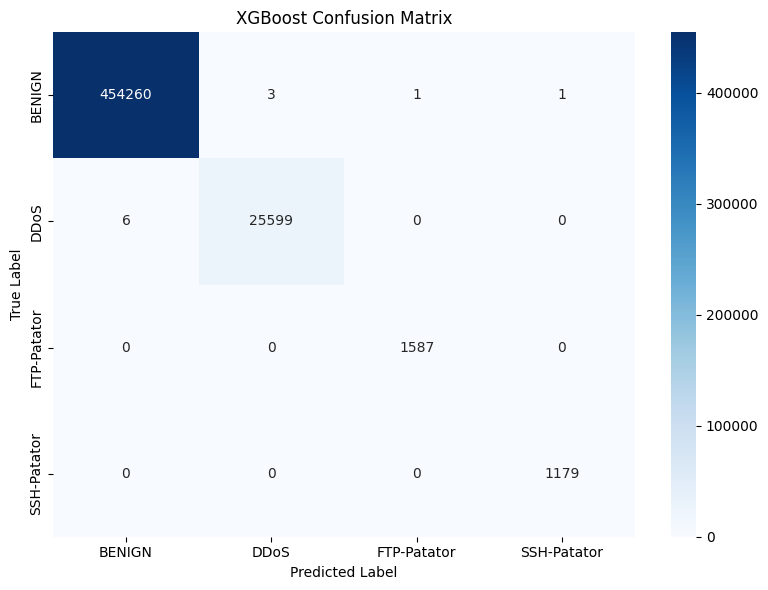

In [33]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [34]:
# Get feature importance from XGBoost
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 20 Most Important Features:\n")
print(feature_importance.head(20).to_string(index=False))

Top 20 Most Important Features:

                    Feature  Importance
      Bwd Packet Length Std    0.327072
          Max Packet Length    0.114978
           act_data_pkt_fwd    0.112890
Total Length of Bwd Packets    0.109604
     Bwd Packet Length Mean    0.062587
     Fwd Packet Length Mean    0.053512
     Total Backward Packets    0.051954
               Flow IAT Std    0.037309
Total Length of Fwd Packets    0.017620
                Fwd IAT Std    0.016946
      Fwd Packet Length Max    0.016283
    Init_Win_bytes_backward    0.012433
       min_seg_size_forward    0.012405
        Subflow Bwd Packets    0.011306
          Subflow Fwd Bytes    0.009962
               Flow IAT Min    0.006549
          Bwd Header Length    0.004139
       Avg Fwd Segment Size    0.003301
           Destination Port    0.003286
              Fwd PSH Flags    0.003286


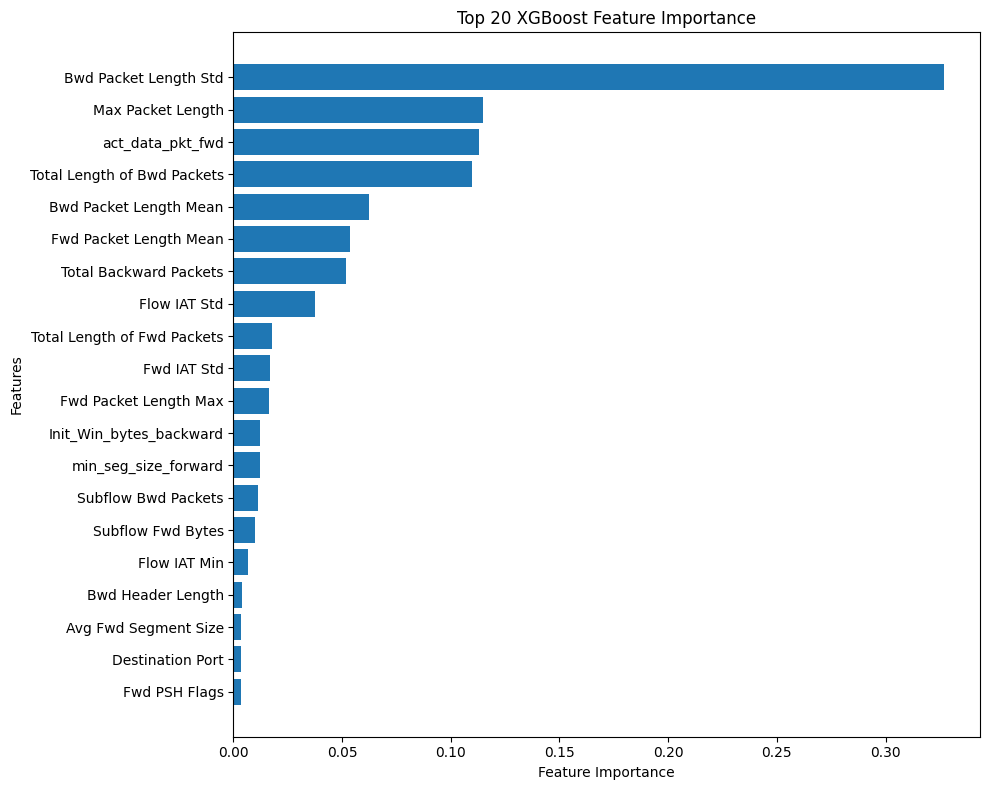

<Figure size 640x480 with 0 Axes>

In [35]:
# Plot top 20 important features
top_20 = feature_importance.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20['Feature'],
    top_20['Importance']
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 XGBoost Feature Importance")

plt.tight_layout()
plt.show()
plt.savefig('/kaggle/working/my_image.png')

In [36]:
# Save feature importance to CSV
feature_importance.to_csv(
    '/kaggle/working/xgboost_feature_importance.csv',
    index=False
)

print("Feature importance saved successfully.")
print("File: /kaggle/working/xgboost_feature_importance.csv")

Feature importance saved successfully.
File: /kaggle/working/xgboost_feature_importance.csv


In [37]:
# Save the trained XGBoost model

model_path = "/kaggle/working/xgboost_model.json"

xgb_model.save_model(model_path)

print("XGBoost model saved successfully.")
print("File:", model_path)

XGBoost model saved successfully.
File: /kaggle/working/xgboost_model.json


In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Starting 5-Fold Cross-Validation...")

cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=1
)

print("\n5-Fold Cross-Validation Results:")
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i} Accuracy: {score:.6f}")

print("\nMean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Starting 5-Fold Cross-Validation...

5-Fold Cross-Validation Results:
Fold 1 Accuracy: 0.999977
Fold 2 Accuracy: 0.999982
Fold 3 Accuracy: 0.999984
Fold 4 Accuracy: 0.999984
Fold 5 Accuracy: 0.999961

Mean CV Accuracy: 0.9999777264513087
Standard Deviation: 8.76000070895661e-06


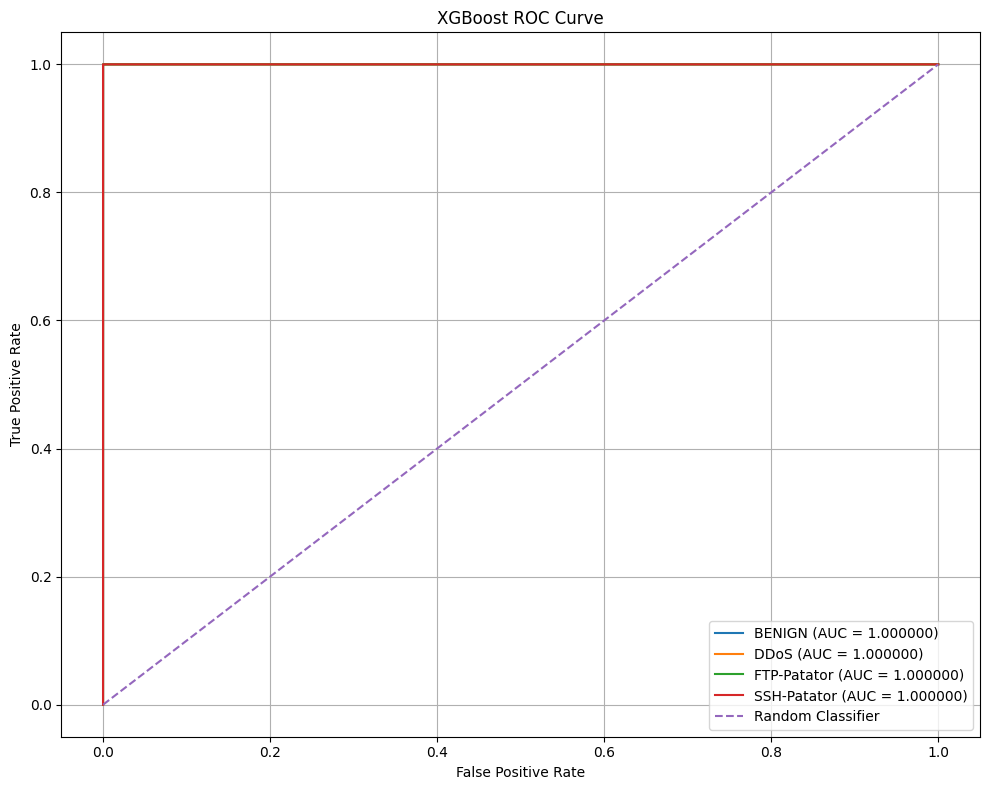

In [39]:
# Generate probability predictions
y_test_proba = xgb_model.predict_proba(X_test)

# Plot ROC curve for each class
plt.figure(figsize=(10, 8))

for i, class_name in enumerate(label_encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test == i,
        y_test_proba[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.6f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [40]:
# Print AUC score for each class

print("========== XGBoost AUC Scores ==========\n")

for i, class_name in enumerate(label_encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test == i,
        y_test_proba[:, i]
    )

    roc_auc = auc(fpr, tpr)

    print(f"{class_name}: AUC = {roc_auc:.6f}")

========== XGBoost AUC Scores ==========

BENIGN: AUC = 1.000000
DDoS: AUC = 1.000000
FTP-Patator: AUC = 1.000000
SSH-Patator: AUC = 1.000000


In [41]:
# Create a summary of XGBoost performance

results = {
    "Training Accuracy": train_accuracy,
    "Training Precision": train_precision,
    "Training Recall": train_recall,
    "Training F1 Score": train_f1,
    "Testing Accuracy": test_accuracy,
    "Testing Precision": test_precision,
    "Testing Recall": test_recall,
    "Testing F1 Score": test_f1,
    "Mean CV Accuracy": cv_scores.mean(),
    "CV Standard Deviation": cv_scores.std()
}

results_df = pd.DataFrame(
    results.items(),
    columns=["Metric", "Value"]
)

print(results_df)

# Save results
results_df.to_csv(
    "/kaggle/working/xgboost_results.csv",
    index=False
)

print("\nResults saved successfully.")
print("File: /kaggle/working/xgboost_results.csv")

                  Metric     Value
0      Training Accuracy  0.999991
1     Training Precision  0.999991
2        Training Recall  0.999991
3      Training F1 Score  0.999991
4       Testing Accuracy  0.999977
5      Testing Precision  0.999977
6         Testing Recall  0.999977
7       Testing F1 Score  0.999977
8       Mean CV Accuracy  0.999978
9  CV Standard Deviation  0.000009

Results saved successfully.
File: /kaggle/working/xgboost_results.csv


In [42]:
print("========== FINAL XGBOOST SUMMARY ==========\n")

print("Dataset:")
print("Total samples :", len(df))
print("Total features:", X.shape[1])
print("Number of classes:", y.nunique())

print("\nClasses:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{i} = {class_name}")

print("\nTrain-Test Split:")
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nPerformance:")
print(f"Training Accuracy : {train_accuracy:.6f}")
print(f"Testing Accuracy  : {test_accuracy:.6f}")
print(f"Testing Precision : {test_precision:.6f}")
print(f"Testing Recall    : {test_recall:.6f}")
print(f"Testing F1 Score  : {test_f1:.6f}")

print("\n5-Fold Cross-Validation:")
print(f"Mean Accuracy     : {cv_scores.mean():.6f}")
print(f"Standard Deviation: {cv_scores.std():.6f}")

print("\nModel files:")
print("XGBoost model       : /kaggle/working/xgboost_model.json")
print("Feature importance  : /kaggle/working/xgboost_feature_importance.csv")
print("Evaluation results  : /kaggle/working/xgboost_results.csv")

========== FINAL XGBOOST SUMMARY ==========

Dataset:
Total samples : 2413177
Total features: 78
Number of classes: 4

Classes:
0 = BENIGN
1 = DDoS
2 = FTP-Patator
3 = SSH-Patator

Train-Test Split:
Training samples: 1930541
Testing samples : 482636

Performance:
Training Accuracy : 0.999991
Testing Accuracy  : 0.999977
Testing Precision : 0.999977
Testing Recall    : 0.999977
Testing F1 Score  : 0.999977

5-Fold Cross-Validation:
Mean Accuracy     : 0.999978
Standard Deviation: 0.000009

Model files:
XGBoost model       : /kaggle/working/xgboost_model.json
Feature importance  : /kaggle/working/xgboost_feature_importance.csv
Evaluation results  : /kaggle/working/xgboost_results.csv


In [43]:
# Generate detailed classification report
report_dict = classification_report(
    y_test,
    y_test_pred,
    target_names=label_encoder.classes_,
    output_dict=True
)

# Convert report to DataFrame
report_df = pd.DataFrame(report_dict).transpose()

# Display report
print("========== DETAILED CLASSIFICATION REPORT ==========\n")
print(report_df)

# Save report
report_df.to_csv(
    "/kaggle/working/xgboost_classification_report.csv"
)

print("\nClassification report saved successfully.")
print("File: /kaggle/working/xgboost_classification_report.csv")

========== DETAILED CLASSIFICATION REPORT ==========

              precision    recall  f1-score        support
BENIGN         0.999987  0.999989  0.999988  454265.000000
DDoS           0.999883  0.999766  0.999824   25605.000000
FTP-Patator    0.999370  1.000000  0.999685    1587.000000
SSH-Patator    0.999153  1.000000  0.999576    1179.000000
accuracy       0.999977  0.999977  0.999977       0.999977
macro avg      0.999598  0.999939  0.999768  482636.000000
weighted avg   0.999977  0.999977  0.999977  482636.000000

Classification report saved successfully.
File: /kaggle/working/xgboost_classification_report.csv


In [44]:
import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

print("SHAP and LIME libraries imported successfully.")

SHAP and LIME libraries imported successfully.


In [45]:
# Create SHAP TreeExplainer for the trained XGBoost model

explainer = shap.TreeExplainer(xgb_model)

print("SHAP TreeExplainer created successfully.")

SHAP TreeExplainer created successfully.


In [46]:
# Use a sample of the test data for SHAP analysis
# This reduces computation time while keeping the analysis representative.

shap_sample_size = 2000

X_shap = X_test.sample(
    n=shap_sample_size,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

# Calculate SHAP values
print("\nCalculating SHAP values...")

shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed.")
print("SHAP type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"Class {i} SHAP shape:", values.shape)
else:
    print("SHAP shape:", shap_values.shape)

SHAP sample shape: (2000, 78)

Calculating SHAP values...
SHAP calculation completed.
SHAP type: <class 'numpy.ndarray'>
SHAP shape: (2000, 78, 4)


In [47]:
# Calculate mean absolute SHAP importance across:
# 2000 samples and all 4 target classes

shap_importance = np.mean(
    np.abs(shap_values),
    axis=(0, 2)
)

shap_importance_df = pd.DataFrame({
    'Feature': X_shap.columns,
    'SHAP Importance': shap_importance
})

# Sort from highest to lowest importance
shap_importance_df = shap_importance_df.sort_values(
    by='SHAP Importance',
    ascending=False
).reset_index(drop=True)

print("Top 20 features based on SHAP importance:\n")
print(shap_importance_df.head(20).to_string(index=False))

Top 20 features based on SHAP importance:

                    Feature  SHAP Importance
           Destination Port         1.076818
      Fwd Packet Length Max         0.717646
     Fwd Packet Length Mean         0.287318
Total Length of Fwd Packets         0.277943
     Init_Win_bytes_forward         0.162595
      Bwd Packet Length Std         0.161144
       min_seg_size_forward         0.140380
          Bwd Header Length         0.126333
    Init_Win_bytes_backward         0.111436
     Total Backward Packets         0.108151
          Max Packet Length         0.078405
          Subflow Fwd Bytes         0.073890
       Avg Fwd Segment Size         0.062602
           act_data_pkt_fwd         0.060836
Total Length of Bwd Packets         0.050513
         Packet Length Mean         0.049992
               Flow IAT Min         0.041219
          Fwd Header Length         0.036820
      Bwd Packet Length Min         0.036801
               Flow IAT Std         0.031676


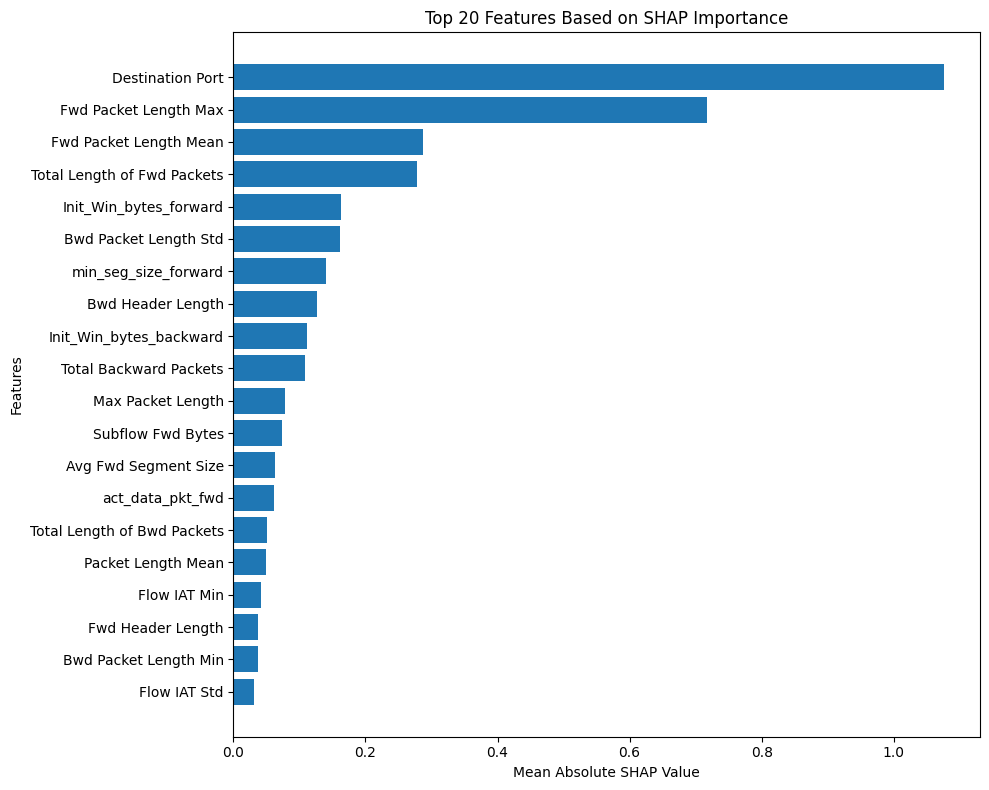

In [48]:
# Plot top 20 SHAP features

top_20_shap = shap_importance_df.head(20).sort_values(
    by='SHAP Importance',
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_20_shap['Feature'],
    top_20_shap['SHAP Importance']
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Top 20 Features Based on SHAP Importance")

plt.tight_layout()
plt.show()

In [49]:
# Calculate cumulative SHAP importance

shap_importance_df['Cumulative Importance'] = (
    shap_importance_df['SHAP Importance'].cumsum()
    / shap_importance_df['SHAP Importance'].sum()
)

# Find the minimum number of features needed to reach 95% importance
num_features_95 = (
    shap_importance_df['Cumulative Importance'] <= 0.95
).sum() + 1

print("Number of features required for 95% SHAP importance:", num_features_95)

print("\nSHAP feature importance with cumulative importance:\n")
print(
    shap_importance_df.head(num_features_95).to_string(index=False)
)

Number of features required for 95% SHAP importance: 33

SHAP feature importance with cumulative importance:

                    Feature  SHAP Importance  Cumulative Importance
           Destination Port         1.076818               0.255633
      Fwd Packet Length Max         0.717646               0.426000
     Fwd Packet Length Mean         0.287318               0.494208
Total Length of Fwd Packets         0.277943               0.560191
     Init_Win_bytes_forward         0.162595               0.598790
      Bwd Packet Length Std         0.161144               0.637046
       min_seg_size_forward         0.140380               0.670371
          Bwd Header Length         0.126333               0.700362
    Init_Win_bytes_backward         0.111436               0.726817
     Total Backward Packets         0.108151               0.752492
          Max Packet Length         0.078405               0.771105
          Subflow Fwd Bytes         0.073890               0.788646
      

In [50]:
# Select the top features that together provide approximately 95% SHAP importance

selected_features = shap_importance_df.head(num_features_95)['Feature'].tolist()

X_shap_reduced = X[selected_features]

print("Number of selected features:", len(selected_features))

print("\nSelected features:")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

print("\nReduced feature matrix shape:", X_shap_reduced.shape)

Number of selected features: 33

Selected features:
1. Destination Port
2. Fwd Packet Length Max
3. Fwd Packet Length Mean
4. Total Length of Fwd Packets
5. Init_Win_bytes_forward
6. Bwd Packet Length Std
7. min_seg_size_forward
8. Bwd Header Length
9. Init_Win_bytes_backward
10. Total Backward Packets
11. Max Packet Length
12. Subflow Fwd Bytes
13. Avg Fwd Segment Size
14. act_data_pkt_fwd
15. Total Length of Bwd Packets
16. Packet Length Mean
17. Flow IAT Min
18. Fwd Header Length
19. Bwd Packet Length Min
20. Flow IAT Std
21. Average Packet Size
22. Fwd IAT Mean
23. Fwd IAT Min
24. Bwd Packets/s
25. URG Flag Count
26. Bwd Packet Length Mean
27. ACK Flag Count
28. Fwd IAT Std
29. Flow IAT Max
30. Flow Duration
31. Fwd Packets/s
32. Fwd Packet Length Std
33. Flow Bytes/s

Reduced feature matrix shape: (2413177, 33)


In [51]:


X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

print("Reduced training feature shape:", X_train_reduced.shape)
print("Reduced testing feature shape :", X_test_reduced.shape)

print("\nTraining labels shape:", y_train.shape)
print("Testing labels shape :", y_test.shape)

Reduced training feature shape: (1930541, 33)
Reduced testing feature shape : (482636, 33)

Training labels shape: (1930541,)
Testing labels shape : (482636,)


In [52]:
# Define a new XGBoost model using the 33 SHAP-selected features

xgb_shap_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

print("SHAP-reduced XGBoost model defined successfully.")

SHAP-reduced XGBoost model defined successfully.


In [53]:
print("Starting SHAP-reduced XGBoost training...")

xgb_shap_model.fit(
    X_train_reduced,
    y_train
)

print("SHAP-reduced XGBoost training completed successfully.")

Starting SHAP-reduced XGBoost training...
SHAP-reduced XGBoost training completed successfully.


In [54]:
# Generate predictions for SHAP-reduced XGBoost

y_train_pred_shap = xgb_shap_model.predict(X_train_reduced)
y_test_pred_shap = xgb_shap_model.predict(X_test_reduced)

print("SHAP-reduced predictions generated successfully.")

print("Training predictions shape:", y_train_pred_shap.shape)
print("Testing predictions shape :", y_test_pred_shap.shape)

SHAP-reduced predictions generated successfully.
Training predictions shape: (1930541,)
Testing predictions shape : (482636,)


In [55]:
# Calculate performance metrics for SHAP-reduced XGBoost

train_accuracy_shap = accuracy_score(
    y_train,
    y_train_pred_shap
)

train_precision_shap = precision_score(
    y_train,
    y_train_pred_shap,
    average='weighted',
    zero_division=0
)

train_recall_shap = recall_score(
    y_train,
    y_train_pred_shap,
    average='weighted',
    zero_division=0
)

train_f1_shap = f1_score(
    y_train,
    y_train_pred_shap,
    average='weighted',
    zero_division=0
)

test_accuracy_shap = accuracy_score(
    y_test,
    y_test_pred_shap
)

test_precision_shap = precision_score(
    y_test,
    y_test_pred_shap,
    average='weighted',
    zero_division=0
)

test_recall_shap = recall_score(
    y_test,
    y_test_pred_shap,
    average='weighted',
    zero_division=0
)

test_f1_shap = f1_score(
    y_test,
    y_test_pred_shap,
    average='weighted',
    zero_division=0
)

print("========== SHAP-REDUCED XGBOOST PERFORMANCE ==========")

print("\nTraining Performance:")
print("Accuracy :", train_accuracy_shap)
print("Precision:", train_precision_shap)
print("Recall   :", train_recall_shap)
print("F1 Score :", train_f1_shap)

print("\nTesting Performance:")
print("Accuracy :", test_accuracy_shap)
print("Precision:", test_precision_shap)
print("Recall   :", test_recall_shap)
print("F1 Score :", test_f1_shap)

========== SHAP-REDUCED XGBOOST PERFORMANCE ==========

Training Performance:
Accuracy : 0.9999870502620768
Precision: 0.9999870500401153
Recall   : 0.9999870502620768
F1 Score : 0.9999870497864057

Testing Performance:
Accuracy : 0.9999772084966725
Precision: 0.9999772093771583
Recall   : 0.9999772084966725
F1 Score : 0.9999772081641985


In [56]:
# Classification report for SHAP-reduced XGBoost

print("========== SHAP-REDUCED XGBOOST CLASSIFICATION REPORT ==========\n")

print(
    classification_report(
        y_test,
        y_test_pred_shap,
        target_names=label_encoder.classes_,
        digits=6
    )
)

========== SHAP-REDUCED XGBOOST CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

      BENIGN   0.999985  0.999991  0.999988    454265
        DDoS   0.999883  0.999727  0.999805     25605
 FTP-Patator   1.000000  1.000000  1.000000      1587
 SSH-Patator   0.999153  1.000000  0.999576      1179

    accuracy                       0.999977    482636
   macro avg   0.999755  0.999929  0.999842    482636
weighted avg   0.999977  0.999977  0.999977    482636



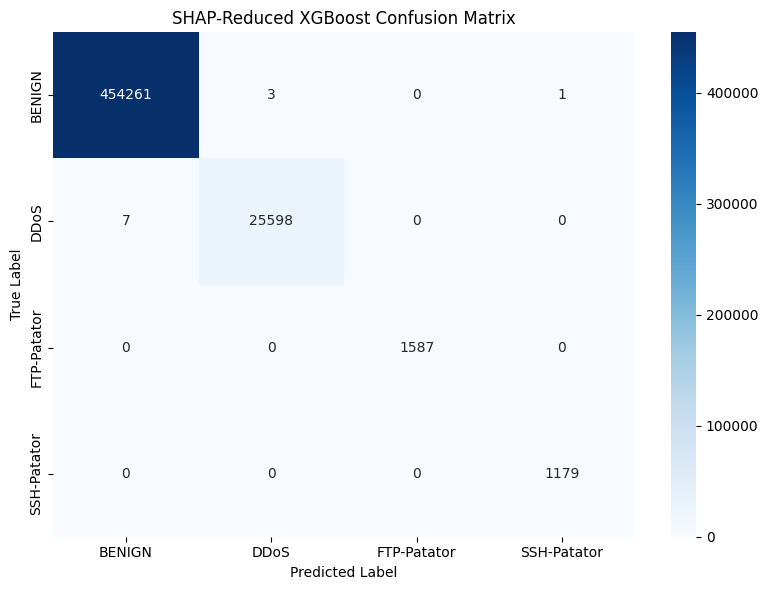

In [57]:
# Generate confusion matrix for SHAP-reduced XGBoost

cm_shap = confusion_matrix(
    y_test,
    y_test_pred_shap
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_shap,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("SHAP-Reduced XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [58]:
# 5-Fold Stratified Cross-Validation for SHAP-reduced XGBoost

cv_shap = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Starting 5-Fold Cross-Validation for SHAP-reduced XGBoost...")

cv_scores_shap = cross_val_score(
    xgb_shap_model,
    X_train_reduced,
    y_train,
    cv=cv_shap,
    scoring='accuracy',
    n_jobs=1
)

print("\nSHAP-Reduced XGBoost 5-Fold Cross-Validation Results:")

for i, score in enumerate(cv_scores_shap, start=1):
    print(f"Fold {i} Accuracy: {score:.6f}")

print("\nMean CV Accuracy:", cv_scores_shap.mean())
print("Standard Deviation:", cv_scores_shap.std())

Starting 5-Fold Cross-Validation for SHAP-reduced XGBoost...

SHAP-Reduced XGBoost 5-Fold Cross-Validation Results:
Fold 1 Accuracy: 0.999972
Fold 2 Accuracy: 0.999979
Fold 3 Accuracy: 0.999982
Fold 4 Accuracy: 0.999984
Fold 5 Accuracy: 0.999961

Mean CV Accuracy: 0.9999756544948507
Standard Deviation: 8.448150494668652e-06


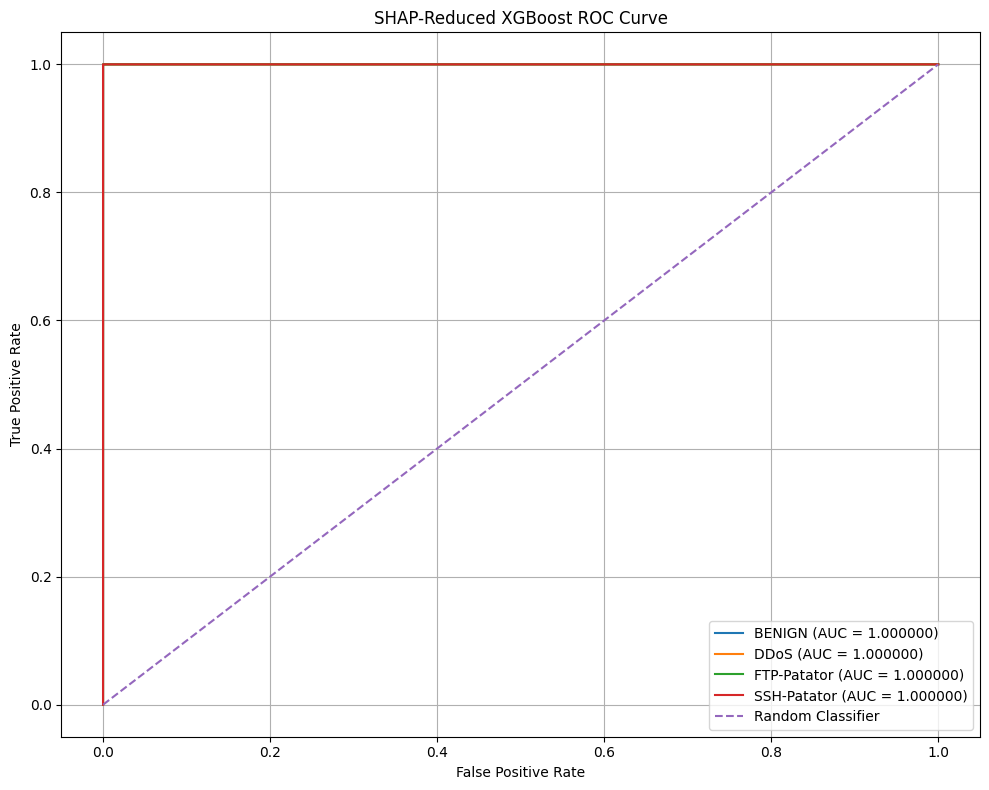

In [59]:
# Generate probability predictions
y_test_proba_shap = xgb_shap_model.predict_proba(X_test_reduced)

# Plot ROC curve for each class
plt.figure(figsize=(10, 8))

for i, class_name in enumerate(label_encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test == i,
        y_test_proba_shap[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.6f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SHAP-Reduced XGBoost ROC Curve")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [60]:
# Print AUC score for each class

print("========== SHAP-REDUCED XGBOOST AUC SCORES ==========\n")

auc_scores_shap = {}

for i, class_name in enumerate(label_encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test == i,
        y_test_proba_shap[:, i]
    )

    roc_auc = auc(fpr, tpr)

    auc_scores_shap[class_name] = roc_auc

    print(f"{class_name}: AUC = {roc_auc:.6f}")

========== SHAP-REDUCED XGBOOST AUC SCORES ==========

BENIGN: AUC = 1.000000
DDoS: AUC = 1.000000
FTP-Patator: AUC = 1.000000
SSH-Patator: AUC = 1.000000


In [61]:
# Create final results table for SHAP-reduced XGBoost

shap_results = {
    "Training Accuracy": train_accuracy_shap,
    "Training Precision": train_precision_shap,
    "Training Recall": train_recall_shap,
    "Training F1 Score": train_f1_shap,
    "Testing Accuracy": test_accuracy_shap,
    "Testing Precision": test_precision_shap,
    "Testing Recall": test_recall_shap,
    "Testing F1 Score": test_f1_shap,
    "Mean CV Accuracy": cv_scores_shap.mean(),
    "CV Standard Deviation": cv_scores_shap.std(),
    "Number of Original Features": X.shape[1],
    "Number of SHAP-Selected Features": len(selected_features)
}

shap_results_df = pd.DataFrame(
    shap_results.items(),
    columns=["Metric", "Value"]
)

print("========== SHAP-REDUCED XGBOOST RESULTS ==========\n")
print(shap_results_df.to_string(index=False))

# Save results
shap_results_df.to_csv(
    "/kaggle/working/shap_reduced_xgboost_results.csv",
    index=False
)

print("\nResults saved successfully.")
print("File: /kaggle/working/shap_reduced_xgboost_results.csv")

========== SHAP-REDUCED XGBOOST RESULTS ==========

                          Metric     Value
               Training Accuracy  0.999987
              Training Precision  0.999987
                 Training Recall  0.999987
               Training F1 Score  0.999987
                Testing Accuracy  0.999977
               Testing Precision  0.999977
                  Testing Recall  0.999977
                Testing F1 Score  0.999977
                Mean CV Accuracy  0.999976
           CV Standard Deviation  0.000008
     Number of Original Features 78.000000
Number of SHAP-Selected Features 33.000000

Results saved successfully.
File: /kaggle/working/shap_reduced_xgboost_results.csv


In [62]:
# Create a representative sample for LIME
lime_sample_size = 5000

X_lime_background = X_train.sample(
    n=lime_sample_size,
    random_state=42
)

print("LIME background sample shape:", X_lime_background.shape)

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_lime_background.values,
    feature_names=X_lime_background.columns.tolist(),
    class_names=label_encoder.classes_.tolist(),
    mode='classification',
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully.")

LIME background sample shape: (5000, 78)
LIME explainer created successfully.


In [63]:
# Select one test sample for local explanation

sample_index = 0

X_lime_instance = X_test.iloc[sample_index]
y_lime_actual = y_test[sample_index]

print("Sample index:", sample_index)
print("Actual class:", label_encoder.inverse_transform([y_lime_actual])[0])


lime_prediction = xgb_model.predict(
    X_lime_instance.values.reshape(1, -1)
)[0]

print("Predicted class:", label_encoder.inverse_transform([lime_prediction])[0])

Sample index: 0
Actual class: BENIGN
Predicted class: BENIGN


In [64]:
# Generate LIME explanation for the selected test sample

lime_exp = lime_explainer.explain_instance(
    X_lime_instance.values,
    xgb_model.predict_proba,
    num_features=15,
    top_labels=4
)

print("LIME explanation generated successfully.")

print("\nExplained sample:")
print("Actual class   :", label_encoder.inverse_transform([y_lime_actual])[0])
print("Predicted class:", label_encoder.inverse_transform([lime_prediction])[0])

LIME explanation generated successfully.

Explained sample:
Actual class   : BENIGN
Predicted class: BENIGN


In [65]:
# Display the LIME feature weights for the predicted class

predicted_class_index = lime_prediction

lime_feature_weights = lime_exp.as_list(
    label=predicted_class_index
)

print("========== LIME FEATURE WEIGHTS ==========\n")

for feature, weight in lime_feature_weights:
    print(f"{feature}: {weight:.6f}")

========== LIME FEATURE WEIGHTS ==========

Bwd Header Length <= 20.00: 0.147313
Destination Port <= 53.00: -0.113553
20.00 < min_seg_size_forward <= 32.00: -0.043058
FIN Flag Count <= 0.00: 0.039596
3.50 < Total Length of Bwd Packets <= 138.00: -0.037205
Init_Win_bytes_backward <= -1.00: -0.029750
Idle Std <= 0.00: 0.028449
4.04 < Fwd Packets/s <= 49.24: -0.022549
80.00 < Bwd Packet Length Mean <= 165.00: -0.020316
94.00 < Max Packet Length <= 274.00: 0.018677
Bwd Packet Length Std <= 0.00: 0.018555
URG Flag Count <= 0.00: -0.017654
155.00 < Flow IAT Max <= 31212.50: -0.016759
Total Fwd Packets <= 2.00: -0.016396
90.00 < Bwd Packet Length Max <= 207.00: 0.015031


In [66]:
# Save LIME feature weights to a CSV file

lime_df = pd.DataFrame(
    lime_feature_weights,
    columns=["Feature", "Weight"]
)

lime_df.to_csv(
    "/kaggle/working/lime_feature_weights.csv",
    index=False
)

print("LIME feature weights saved successfully.")
print("File: /kaggle/working/lime_feature_weights.csv")

print("\nLIME Feature Weights:")
print(lime_df.to_string(index=False))

LIME feature weights saved successfully.
File: /kaggle/working/lime_feature_weights.csv

LIME Feature Weights:
                                     Feature    Weight
                  Bwd Header Length <= 20.00  0.147313
                   Destination Port <= 53.00 -0.113553
       20.00 < min_seg_size_forward <= 32.00 -0.043058
                      FIN Flag Count <= 0.00  0.039596
3.50 < Total Length of Bwd Packets <= 138.00 -0.037205
            Init_Win_bytes_backward <= -1.00 -0.029750
                            Idle Std <= 0.00  0.028449
               4.04 < Fwd Packets/s <= 49.24 -0.022549
    80.00 < Bwd Packet Length Mean <= 165.00 -0.020316
         94.00 < Max Packet Length <= 274.00  0.018677
               Bwd Packet Length Std <= 0.00  0.018555
                      URG Flag Count <= 0.00 -0.017654
           155.00 < Flow IAT Max <= 31212.50 -0.016759
                   Total Fwd Packets <= 2.00 -0.016396
     90.00 < Bwd Packet Length Max <= 207.00  0.015031


In [67]:
# Save SHAP feature importance to CSV

shap_importance_df.to_csv(
    "/kaggle/working/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully.")
print("File: /kaggle/working/shap_feature_importance.csv")

SHAP feature importance saved successfully.
File: /kaggle/working/shap_feature_importance.csv


In [68]:
# Compare feature model

comparison = pd.DataFrame({
    "Metric": [
        "Number of Features",
        "Training Accuracy",
        "Training Precision",
        "Training Recall",
        "Training F1 Score",
        "Testing Accuracy",
        "Testing Precision",
        "Testing Recall",
        "Testing F1 Score",
        "Mean CV Accuracy",
        "CV Standard Deviation"
    ],
    
    "Original XGBoost": [
        X.shape[1],
        train_accuracy,
        train_precision,
        train_recall,
        train_f1,
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        cv_scores.mean(),
        cv_scores.std()
    ],
    
    "SHAP-Reduced XGBoost": [
        len(selected_features),
        train_accuracy_shap,
        train_precision_shap,
        train_recall_shap,
        train_f1_shap,
        test_accuracy_shap,
        test_precision_shap,
        test_recall_shap,
        test_f1_shap,
        cv_scores_shap.mean(),
        cv_scores_shap.std()
    ]
})

print("========== ORIGINAL vs SHAP-REDUCED XGBOOST ==========\n")
print(comparison.to_string(index=False))

========== ORIGINAL vs SHAP-REDUCED XGBOOST ==========

               Metric  Original XGBoost  SHAP-Reduced XGBoost
   Number of Features         78.000000             33.000000
    Training Accuracy          0.999991              0.999987
   Training Precision          0.999991              0.999987
      Training Recall          0.999991              0.999987
    Training F1 Score          0.999991              0.999987
     Testing Accuracy          0.999977              0.999977
    Testing Precision          0.999977              0.999977
       Testing Recall          0.999977              0.999977
     Testing F1 Score          0.999977              0.999977
     Mean CV Accuracy          0.999978              0.999976
CV Standard Deviation          0.000009              0.000008


In [69]:
# Save the comparison table

comparison.to_csv(
    "/kaggle/working/xgboost_shap_comparison.csv",
    index=False
)

print("Comparison table saved successfully.")
print("File: /kaggle/working/xgboost_shap_comparison.csv")

Comparison table saved successfully.
File: /kaggle/working/xgboost_shap_comparison.csv


In [70]:
print("========== FINAL XGBOOST COMPARISON ==========\n")

print("Original XGBoost:")
print(f"Features          : {X.shape[1]}")
print(f"Testing Accuracy  : {test_accuracy:.6f}")
print(f"Testing Precision : {test_precision:.6f}")
print(f"Testing Recall    : {test_recall:.6f}")
print(f"Testing F1 Score  : {test_f1:.6f}")
print(f"Mean CV Accuracy  : {cv_scores.mean():.6f}")

print("\nSHAP-Reduced XGBoost:")
print(f"Features          : {len(selected_features)}")
print(f"Testing Accuracy  : {test_accuracy_shap:.6f}")
print(f"Testing Precision : {test_precision_shap:.6f}")
print(f"Testing Recall    : {test_recall_shap:.6f}")
print(f"Testing F1 Score  : {test_f1_shap:.6f}")
print(f"Mean CV Accuracy  : {cv_scores_shap.mean():.6f}")

print("\nFeature Reduction:")
print(
    f"{X.shape[1]} → {len(selected_features)} features"
)
print(
    f"Features removed: {X.shape[1] - len(selected_features)}"
)

========== FINAL XGBOOST COMPARISON ==========

Original XGBoost:
Features          : 78
Testing Accuracy  : 0.999977
Testing Precision : 0.999977
Testing Recall    : 0.999977
Testing F1 Score  : 0.999977
Mean CV Accuracy  : 0.999978

SHAP-Reduced XGBoost:
Features          : 33
Testing Accuracy  : 0.999977
Testing Precision : 0.999977
Testing Recall    : 0.999977
Testing F1 Score  : 0.999977
Mean CV Accuracy  : 0.999976

Feature Reduction:
78 → 33 features
Features removed: 45


In [71]:
final_summary = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "SHAP-Reduced XGBoost"
    ],
    "Features": [
        X.shape[1],
        len(selected_features)
    ],
    "Testing Accuracy": [
        test_accuracy,
        test_accuracy_shap
    ],
    "Testing Precision": [
        test_precision,
        test_precision_shap
    ],
    "Testing Recall": [
        test_recall,
        test_recall_shap
    ],
    "Testing F1 Score": [
        test_f1,
        test_f1_shap
    ],
    "Mean CV Accuracy": [
        cv_scores.mean(),
        cv_scores_shap.mean()
    ]
})

final_summary.to_csv(
    "/kaggle/working/final_xgboost_summary.csv",
    index=False
)

print("Final model summary saved successfully.")
print("File: /kaggle/working/final_xgboost_summary.csv")

Final model summary saved successfully.
File: /kaggle/working/final_xgboost_summary.csv


In [72]:
selected_features_df = pd.DataFrame({
    "Feature": selected_features
})

selected_features_df.to_csv(
    "/kaggle/working/selected_shap_features.csv",
    index=False
)

print("Selected SHAP features saved successfully.")
print(f"Number of selected features: {len(selected_features)}")
print("File: /kaggle/working/selected_shap_features.csv")

Selected SHAP features saved successfully.
Number of selected features: 33
File: /kaggle/working/selected_shap_features.csv


In [73]:
import os

final_files = [
    "xgboost_model.json",
    "xgboost_results.csv",
    "xgboost_classification_report.csv",
    "xgboost_feature_importance.csv",
    "shap_feature_importance.csv",
    "lime_feature_weights.csv",
    "shap_reduced_xgboost_results.csv",
    "xgboost_shap_comparison.csv",
    "final_xgboost_summary.csv",
    "selected_shap_features.csv"
]

print("========== FINAL ARTIFACT CHECK ==========\n")

for file in final_files:
    path = f"/kaggle/working/{file}"
    
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {file}  |  {size_mb:.2f} MB")
    else:
        print(f"✗ {file}  |  NOT FOUND")

print("\nArtifact check completed.")

========== FINAL ARTIFACT CHECK ==========

✓ xgboost_model.json  |  0.74 MB
✓ xgboost_results.csv  |  0.00 MB
✓ xgboost_classification_report.csv  |  0.00 MB
✓ xgboost_feature_importance.csv  |  0.00 MB
✓ shap_feature_importance.csv  |  0.00 MB
✓ lime_feature_weights.csv  |  0.00 MB
✓ shap_reduced_xgboost_results.csv  |  0.00 MB
✓ xgboost_shap_comparison.csv  |  0.00 MB
✓ final_xgboost_summary.csv  |  0.00 MB
✓ selected_shap_features.csv  |  0.00 MB

Artifact check completed.


In [74]:
print("========== THESIS FINAL RESULTS ==========\n")

print("Dataset:")
print(f"Total Samples       : {len(df):,}")
print(f"Total Features      : {X.shape[1]}")
print(f"Classes             : {len(label_encoder.classes_)}")
print(f"Class Names         : {list(label_encoder.classes_)}")

print("\nOriginal XGBoost:")
print(f"Features            : {X.shape[1]}")
print(f"Test Accuracy       : {test_accuracy:.6f}")
print(f"Test Precision      : {test_precision:.6f}")
print(f"Test Recall         : {test_recall:.6f}")
print(f"Test F1 Score       : {test_f1:.6f}")
print(f"Mean 5-Fold CV      : {cv_scores.mean():.6f}")

print("\nSHAP-Reduced XGBoost:")
print(f"Features            : {len(selected_features)}")
print(f"Test Accuracy       : {test_accuracy_shap:.6f}")
print(f"Test Precision      : {test_precision_shap:.6f}")
print(f"Test Recall         : {test_recall_shap:.6f}")
print(f"Test F1 Score       : {test_f1_shap:.6f}")
print(f"Mean 5-Fold CV      : {cv_scores_shap.mean():.6f}")

print("\nFeature Reduction:")
print(f"Original Features  : {X.shape[1]}")
print(f"Selected Features  : {len(selected_features)}")
print(f"Removed Features   : {X.shape[1] - len(selected_features)}")
print(
    f"Reduction          : "
    f"{((X.shape[1] - len(selected_features)) / X.shape[1]) * 100:.2f}%"
)

print("\n==========================================")

========== THESIS FINAL RESULTS ==========

Dataset:
Total Samples       : 2,413,177
Total Features      : 78
Classes             : 4
Class Names         : ['BENIGN', 'DDoS', 'FTP-Patator', 'SSH-Patator']

Original XGBoost:
Features            : 78
Test Accuracy       : 0.999977
Test Precision      : 0.999977
Test Recall         : 0.999977
Test F1 Score       : 0.999977
Mean 5-Fold CV      : 0.999978

SHAP-Reduced XGBoost:
Features            : 33
Test Accuracy       : 0.999977
Test Precision      : 0.999977
Test Recall         : 0.999977
Test F1 Score       : 0.999977
Mean 5-Fold CV      : 0.999976

Feature Reduction:
Original Features  : 78
Selected Features  : 33
Removed Features   : 45
Reduction          : 57.69%



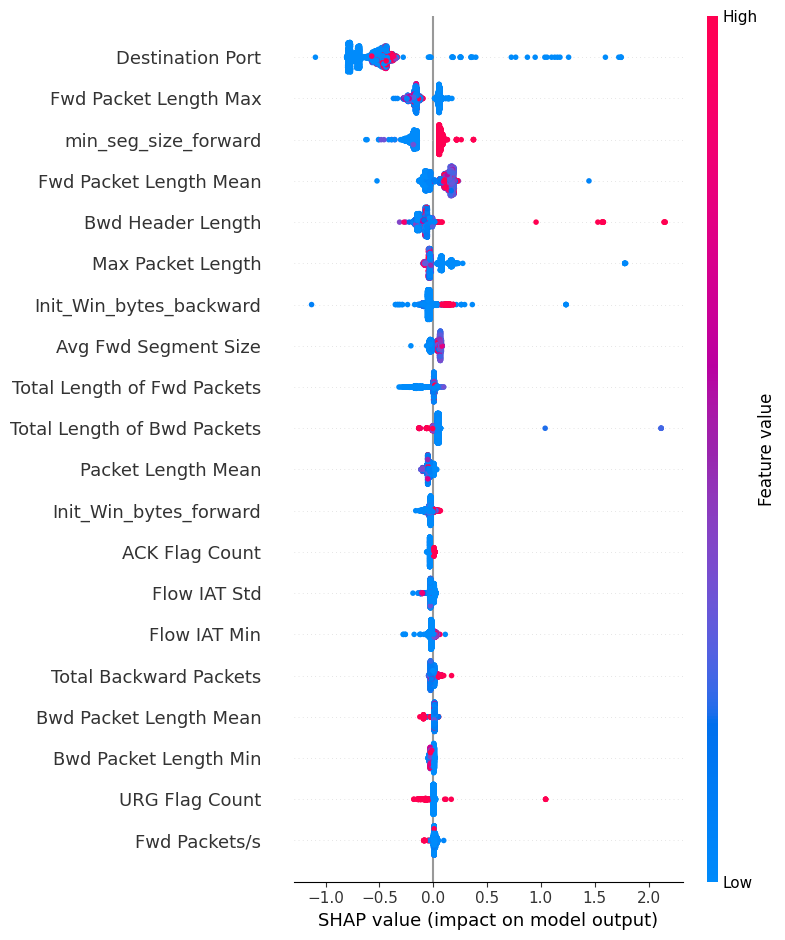

In [75]:
# SHAP Summary Plot

shap.summary_plot(
    shap_values.mean(axis=2),
    X_shap,
    feature_names=X_shap.columns,
    show=True
)

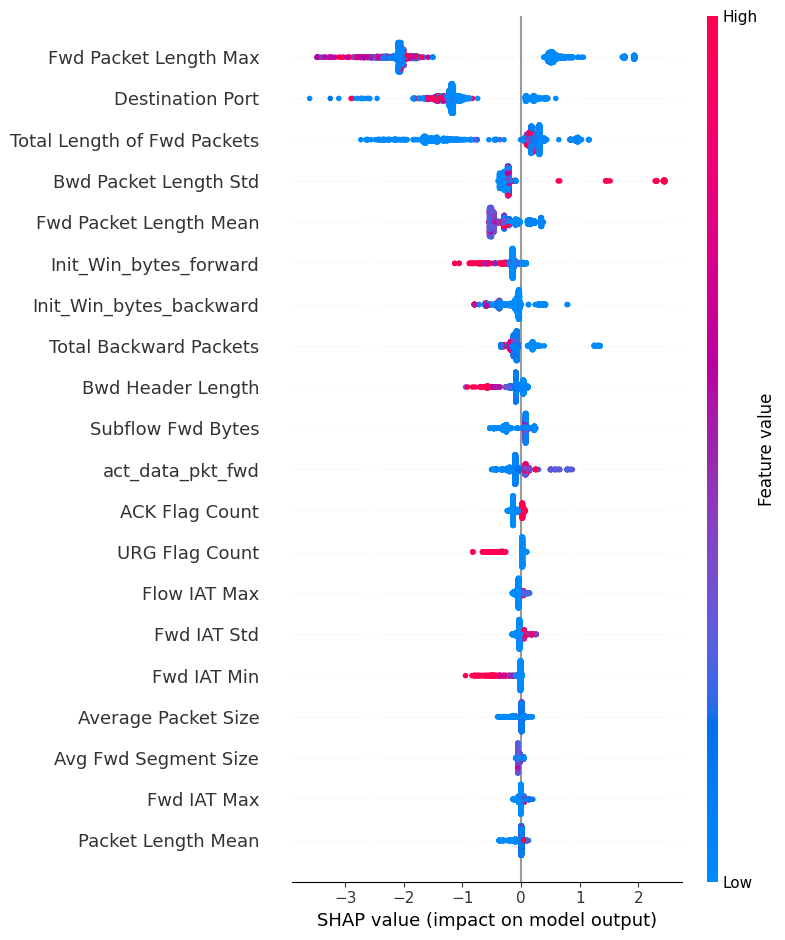

In [76]:
# SHAP Summary Plot for DDoS class

ddos_class_index = 1

shap.summary_plot(
    shap_values[:, :, ddos_class_index],
    X_shap,
    feature_names=X_shap.columns,
    max_display=20,
    show=True
)

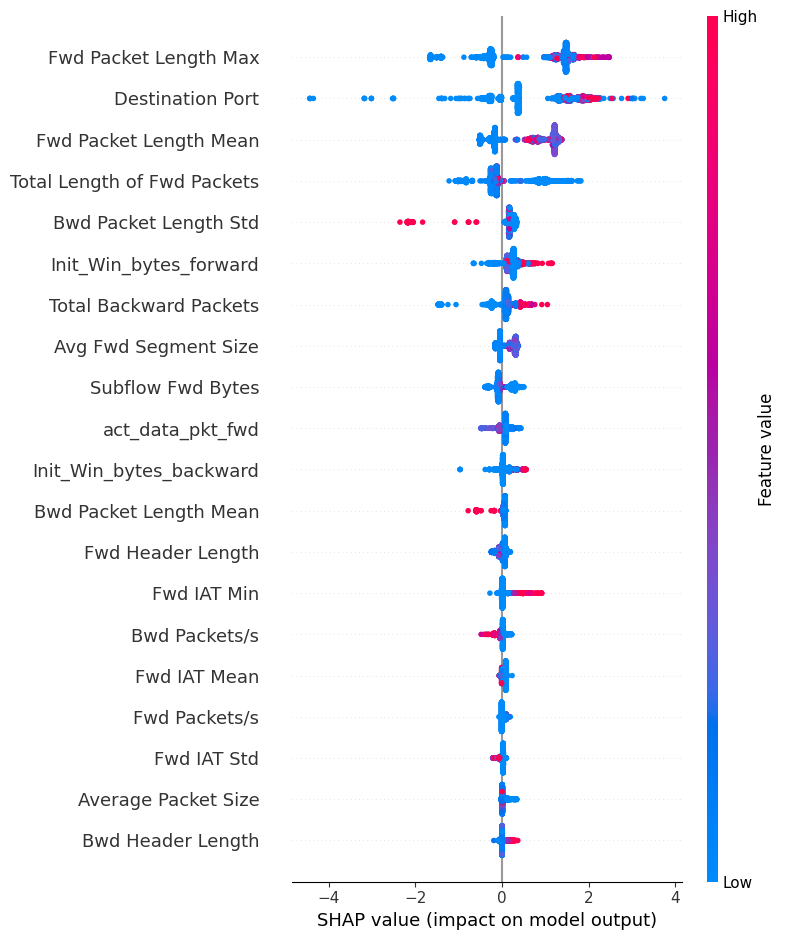

In [77]:
# SHAP Summary Plot for BENIGN class

benign_class_index = 0

shap.summary_plot(
    shap_values[:, :, benign_class_index],
    X_shap,
    feature_names=X_shap.columns,
    max_display=20,
    show=True
)

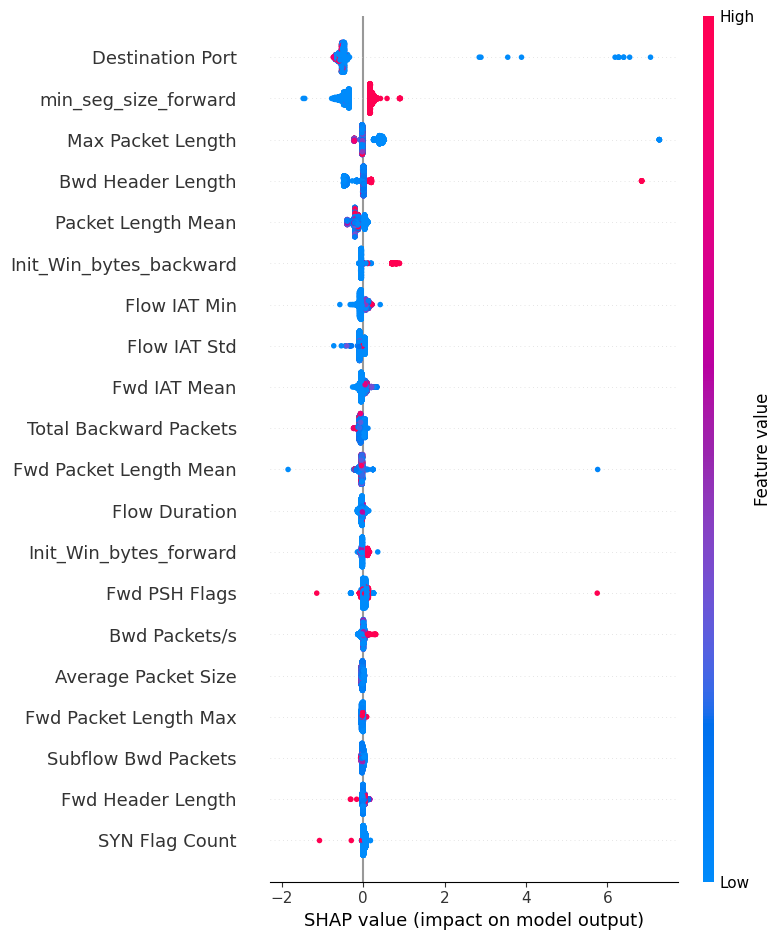

In [78]:
# SHAP Summary Plot for FTP-Patator class

ftp_class_index = 2

shap.summary_plot(
    shap_values[:, :, ftp_class_index],
    X_shap,
    feature_names=X_shap.columns,
    max_display=20,
    show=True
)

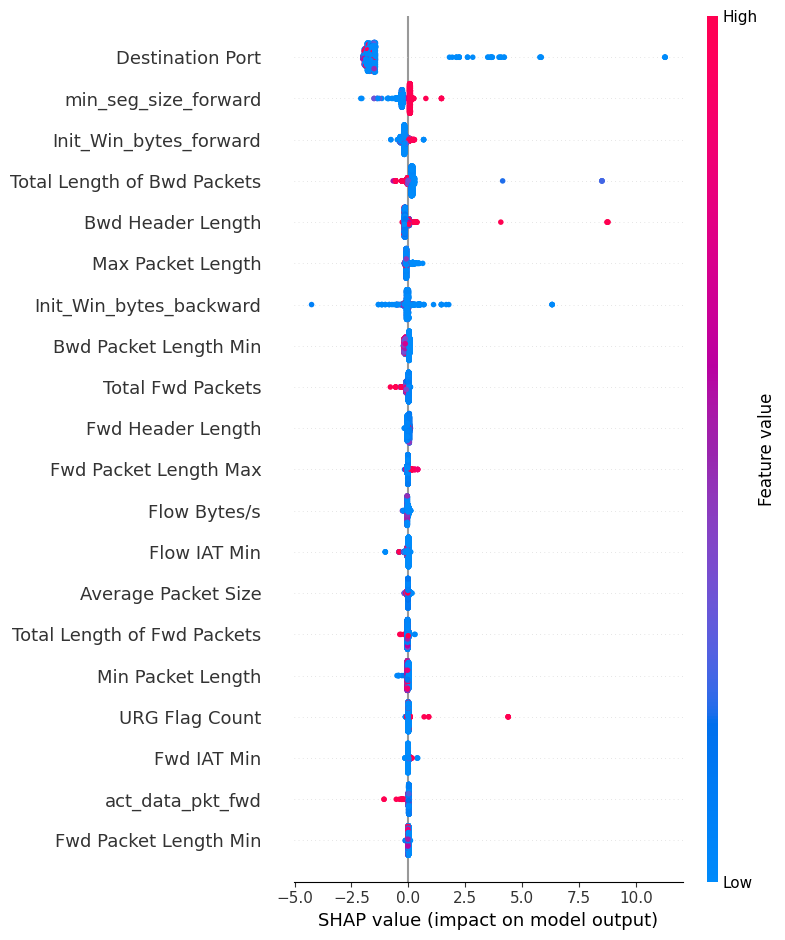

In [79]:
# SHAP Summary Plot for SSH-Patator class

ssh_class_index = 3

shap.summary_plot(
    shap_values[:, :, ssh_class_index],
    X_shap,
    feature_names=X_shap.columns,
    max_display=20,
    show=True
)

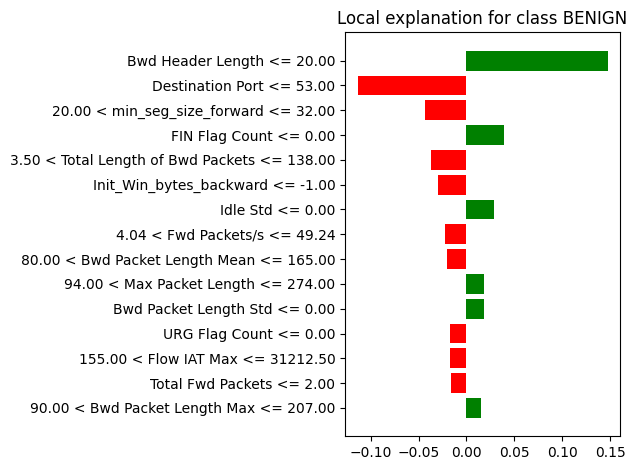

In [80]:
# LIME explanation plot for the selected test instance

lime_exp.as_pyplot_figure(label=lime_prediction)

plt.tight_layout()
plt.show()

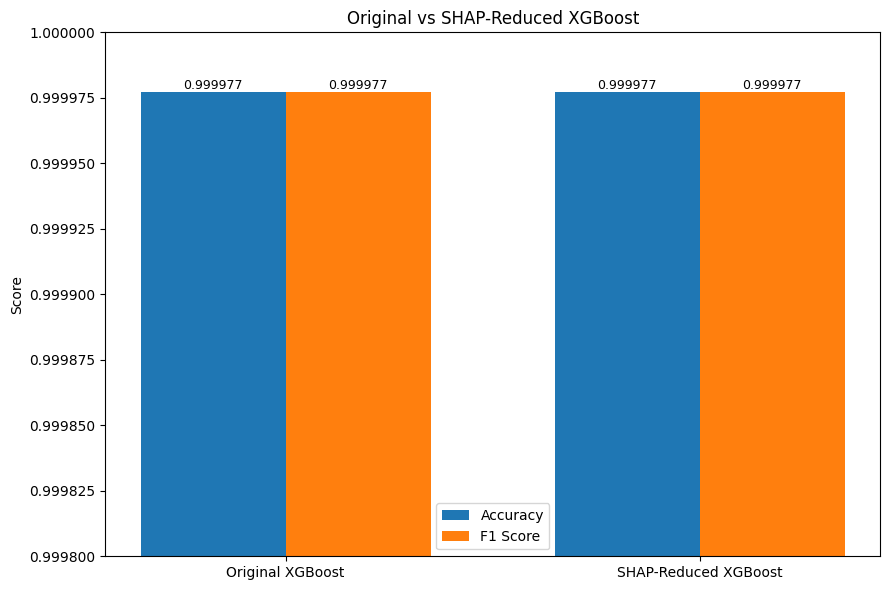

In [81]:
# Original vs SHAP-Reduced XGBoost Performance Comparison

models = ["Original XGBoost", "SHAP-Reduced XGBoost"]

accuracy_values = [test_accuracy, test_accuracy_shap]
f1_values = [test_f1, test_f1_shap]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width/2,
    accuracy_values,
    width,
    label="Accuracy"
)

bars2 = ax.bar(
    x + width/2,
    f1_values,
    width,
    label="F1 Score"
)

ax.set_ylabel("Score")
ax.set_title("Original vs SHAP-Reduced XGBoost")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0.9998, 1.0000)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{bar.get_height():.6f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [82]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
import numpy as np

# Base XGBoost model
xgb_base = XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
param_dist = {
    'n_estimators': [100, 150, 200, 250],
    'max_depth': [4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.5]
}

print("Optimization setup completed.")
print("Search method: RandomizedSearchCV")
print("Number of parameter combinations to test: 10")

Optimization setup completed.
Search method: RandomizedSearchCV
Number of parameter combinations to test: 10


In [83]:
from sklearn.model_selection import train_test_split

print("train_test_split imported successfully.")

train_test_split imported successfully.


In [84]:


X_opt, _, y_opt, _ = train_test_split(
    X_train,
    y_train,
    train_size=150000,
    random_state=42,
    stratify=y_train
)

print("========== OPTIMIZATION DATA ==========")
print(f"Optimization samples : {X_opt.shape[0]:,}")
print(f"Optimization features: {X_opt.shape[1]}")
print(f"Optimization labels   : {y_opt.shape[0]:,}")
print("Test set used        : NO")

========== OPTIMIZATION DATA ==========
Optimization samples : 150,000
Optimization features: 78
Optimization labels   : 150,000
Test set used        : NO


In [85]:
# Hyperparameter Optimization using RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=10,
    scoring='f1_weighted',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_opt, y_opt)

print("\n========== OPTIMIZATION COMPLETED ==========")
print("Best Parameters:")
print(random_search.best_params_)
print(f"\nBest CV F1 Score: {random_search.best_score_:.6f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits

========== OPTIMIZATION COMPLETED ==========
Best Parameters:
{'subsample': 1.0, 'n_estimators': 150, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}

Best CV F1 Score: 0.999913


In [86]:
# Final Optimized XGBoost Model

optimized_xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    min_child_weight=1,
    gamma=0.1,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

optimized_xgb_model.fit(X_train, y_train)

print("Optimized XGBoost training completed successfully.")

Optimized XGBoost training completed successfully.


In [87]:
# Optimized XGBoost predictions and evaluation

y_test_pred_opt = optimized_xgb_model.predict(X_test)

optimized_test_accuracy = accuracy_score(y_test, y_test_pred_opt)
optimized_test_precision = precision_score(
    y_test, y_test_pred_opt, average='weighted'
)
optimized_test_recall = recall_score(
    y_test, y_test_pred_opt, average='weighted'
)
optimized_test_f1 = f1_score(
    y_test, y_test_pred_opt, average='weighted'
)

print("========== OPTIMIZED XGBOOST TEST RESULTS ==========")
print(f"Test Accuracy  : {optimized_test_accuracy:.6f}")
print(f"Test Precision : {optimized_test_precision:.6f}")
print(f"Test Recall    : {optimized_test_recall:.6f}")
print(f"Test F1 Score  : {optimized_test_f1:.6f}")

========== OPTIMIZED XGBOOST TEST RESULTS ==========
Test Accuracy  : 0.999985
Test Precision : 0.999985
Test Recall    : 0.999985
Test F1 Score  : 0.999985


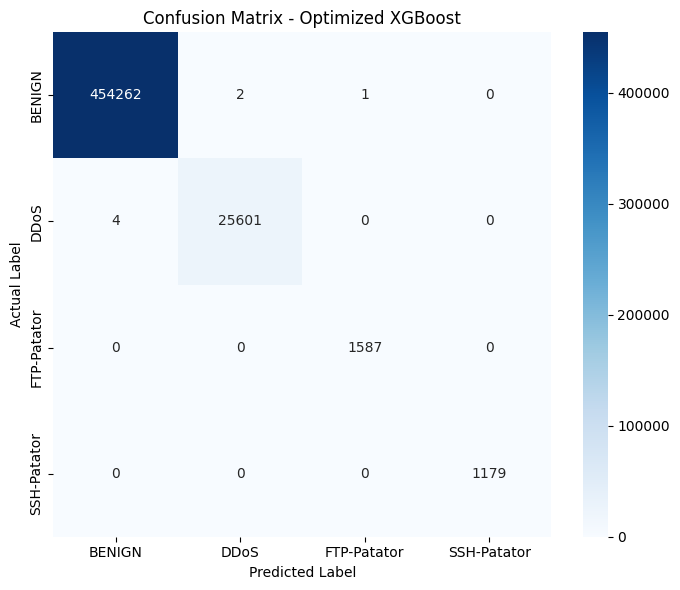

[CV] END colsample_bytree=0.9, gamma=0.1, learning_rate=0.2, max_depth=5, min_child_weight=7, n_estimators=100, subsample=1.0; total time=  10.2s
[CV] END colsample_bytree=0.9, gamma=0.1, learning_rate=0.2, max_depth=5, min_child_weight=7, n_estimators=100, subsample=1.0; total time=  10.1s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.1, max_depth=7, min_child_weight=3, n_estimators=250, subsample=0.7; total time=  24.5s
[CV] END colsample_bytree=1.0, gamma=0.1, learning_rate=0.1, max_depth=6, min_child_weight=1, n_estimators=150, subsample=1.0; total time=  15.0s
[CV] END colsample_bytree=1.0, gamma=0.1, learning_rate=0.1, max_depth=6, min_child_weight=1, n_estimators=150, subsample=1.0; total time=  14.7s
[CV] END colsample_bytree=0.8, gamma=0.5, learning_rate=0.01, max_depth=5, min_child_weight=3, n_estimators=150, subsample=0.7; total time=  15.4s
[CV] END colsample_bytree=1.0, gamma=0.1, learning_rate=0.2, max_depth=4, min_child_weight=5, n_estimators=150, subsample=0.9

In [88]:
# Confusion Matrix for Optimized XGBoost

cm_optimized = confusion_matrix(y_test, y_test_pred_opt)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_optimized,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Optimized XGBoost")
plt.tight_layout()
plt.show()

In [89]:
# 5-Fold Cross-Validation for Optimized XGBoost

optimized_cv_scores = cross_val_score(
    optimized_xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

print("========== OPTIMIZED XGBOOST 5-FOLD CV ==========")

for i, score in enumerate(optimized_cv_scores, 1):
    print(f"Fold {i} F1 Score: {score:.6f}")

print(f"\nMean CV F1 Score: {optimized_cv_scores.mean():.6f}")
print(f"Std CV F1 Score : {optimized_cv_scores.std():.6f}")

========== OPTIMIZED XGBOOST 5-FOLD CV ==========
Fold 1 F1 Score: 0.999982
Fold 2 F1 Score: 0.999966
Fold 3 F1 Score: 0.999990
Fold 4 F1 Score: 0.999987
Fold 5 F1 Score: 0.999982

Mean CV F1 Score: 0.999981
Std CV F1 Score : 0.000008


In [90]:
# SHAP explanation for the Optimized XGBoost model

optimized_explainer = shap.TreeExplainer(optimized_xgb_model)

optimized_shap_values = optimized_explainer.shap_values(X_shap)

print("========== OPTIMIZED XGBOOST SHAP ==========")
print("SHAP calculation completed.")
print("SHAP type  :", type(optimized_shap_values))
print("SHAP shape :", optimized_shap_values.shape)

========== OPTIMIZED XGBOOST SHAP ==========
SHAP calculation completed.
SHAP type  : <class 'numpy.ndarray'>
SHAP shape : (2000, 78, 4)


In [91]:
# SHAP feature importance using training data only

X_shap_opt = X_opt.sample(
    n=2000,
    random_state=42
)

shap_values_opt_train = optimized_explainer.shap_values(
    X_shap_opt
)

shap_importance_opt = np.mean(
    np.abs(shap_values_opt_train),
    axis=(0, 2)
)

shap_importance_opt_df = pd.DataFrame({
    "Feature": X_shap_opt.columns,
    "SHAP Importance": shap_importance_opt
}).sort_values(
    by="SHAP Importance",
    ascending=False
).reset_index(drop=True)

print("========== OPTIMIZED XGBOOST SHAP IMPORTANCE ==========\n")
print(shap_importance_opt_df.head(20).to_string(index=False))

========== OPTIMIZED XGBOOST SHAP IMPORTANCE ==========

                    Feature  SHAP Importance
           Destination Port         1.101547
      Fwd Packet Length Max         1.079912
    Init_Win_bytes_backward         0.316323
Total Length of Fwd Packets         0.308292
     Init_Win_bytes_forward         0.253868
       min_seg_size_forward         0.197399
      Bwd Packet Length Std         0.164443
               Flow IAT Min         0.154336
     Total Backward Packets         0.124880
      Bwd Packet Length Min         0.113056
              Bwd Packets/s         0.107405
             ACK Flag Count         0.087955
              Flow Duration         0.087723
               Flow IAT Std         0.083080
                Fwd IAT Std         0.074539
              Flow IAT Mean         0.073771
          Fwd Header Length         0.071090
     Fwd Packet Length Mean         0.067716
           act_data_pkt_fwd         0.061120
               Fwd IAT Mean         0.05285

In [92]:
# Select features covering 95% cumulative SHAP importance

shap_importance_opt_df["Cumulative Importance"] = (
    shap_importance_opt_df["SHAP Importance"].cumsum()
    / shap_importance_opt_df["SHAP Importance"].sum()
)

num_features_95_opt = (
    shap_importance_opt_df["Cumulative Importance"] <= 0.95
).sum() + 1

selected_features_opt = (
    shap_importance_opt_df
    .head(num_features_95_opt)["Feature"]
    .tolist()
)

print("========== OPTIMIZED SHAP FEATURE SELECTION ==========")
print(f"Original features : {X.shape[1]}")
print(f"Selected features : {len(selected_features_opt)}")
print(f"Features removed  : {X.shape[1] - len(selected_features_opt)}")
print(
    f"Reduction         : "
    f"{((X.shape[1] - len(selected_features_opt)) / X.shape[1]) * 100:.2f}%"
)

print("\nSelected Features:")
for i, feature in enumerate(selected_features_opt, 1):
    print(f"{i}. {feature}")

========== OPTIMIZED SHAP FEATURE SELECTION ==========
Original features : 78
Selected features : 29
Features removed  : 49
Reduction         : 62.82%

Selected Features:
1. Destination Port
2. Fwd Packet Length Max
3. Init_Win_bytes_backward
4. Total Length of Fwd Packets
5. Init_Win_bytes_forward
6. min_seg_size_forward
7. Bwd Packet Length Std
8. Flow IAT Min
9. Total Backward Packets
10. Bwd Packet Length Min
11. Bwd Packets/s
12. ACK Flag Count
13. Flow Duration
14. Flow IAT Std
15. Fwd IAT Std
16. Flow IAT Mean
17. Fwd Header Length
18. Fwd Packet Length Mean
19. act_data_pkt_fwd
20. Fwd IAT Mean
21. Fwd IAT Min
22. Flow IAT Max
23. URG Flag Count
24. Fwd Packets/s
25. Bwd IAT Mean
26. Bwd Header Length
27. Packet Length Mean
28. Fwd Packet Length Std
29. FIN Flag Count


In [93]:
# Create training and test data using optimized SHAP-selected features

X_train_opt_shap = X_train[selected_features_opt]
X_test_opt_shap = X_test[selected_features_opt]

print("========== OPTIMIZED SHAP-REDUCED DATA ==========")
print(f"Training shape : {X_train_opt_shap.shape}")
print(f"Testing shape  : {X_test_opt_shap.shape}")
print(f"Features used  : {len(selected_features_opt)}")


========== OPTIMIZED SHAP-REDUCED DATA ==========
Training shape : (1930541, 29)
Testing shape  : (482636, 29)
Features used  : 29


In [94]:
# Final Optimized + SHAP-Reduced XGBoost

optimized_shap_xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    min_child_weight=1,
    gamma=0.1,
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

optimized_shap_xgb_model.fit(
    X_train_opt_shap,
    y_train
)

print("Optimized + SHAP-Reduced XGBoost training completed successfully.")

Optimized + SHAP-Reduced XGBoost training completed successfully.


In [95]:
# Final Optimized + SHAP-Reduced XGBoost evaluation

y_test_pred_opt_shap = optimized_shap_xgb_model.predict(
    X_test_opt_shap
)

final_opt_shap_accuracy = accuracy_score(
    y_test, y_test_pred_opt_shap
)

final_opt_shap_precision = precision_score(
    y_test, y_test_pred_opt_shap,
    average='weighted'
)

final_opt_shap_recall = recall_score(
    y_test, y_test_pred_opt_shap,
    average='weighted'
)

final_opt_shap_f1 = f1_score(
    y_test, y_test_pred_opt_shap,
    average='weighted'
)

print("========== FINAL OPTIMIZED + SHAP-REDUCED ==========")
print(f"Features       : {len(selected_features_opt)}")
print(f"Test Accuracy  : {final_opt_shap_accuracy:.6f}")
print(f"Test Precision : {final_opt_shap_precision:.6f}")
print(f"Test Recall    : {final_opt_shap_recall:.6f}")
print(f"Test F1 Score  : {final_opt_shap_f1:.6f}")

========== FINAL OPTIMIZED + SHAP-REDUCED ==========
Features       : 29
Test Accuracy  : 0.999983
Test Precision : 0.999983
Test Recall    : 0.999983
Test F1 Score  : 0.999983


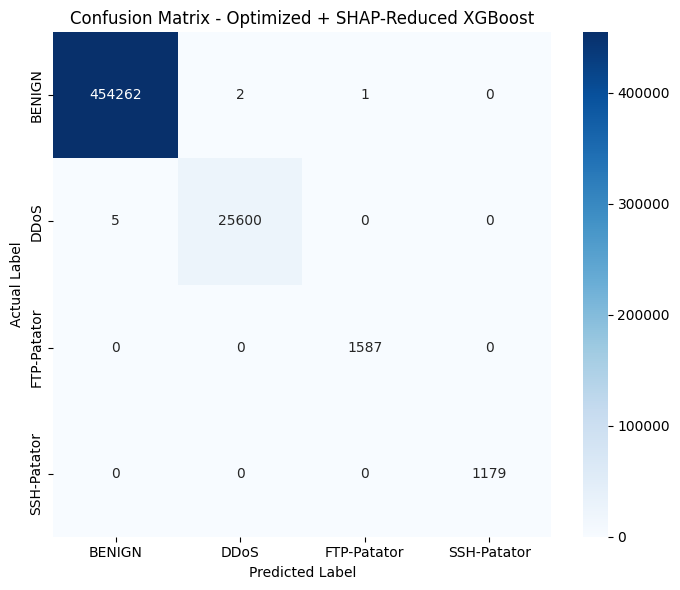

In [96]:
# Final Optimized + SHAP-Reduced Confusion Matrix

cm_final = confusion_matrix(
    y_test,
    y_test_pred_opt_shap
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_final,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Optimized + SHAP-Reduced XGBoost")
plt.tight_layout()
plt.show()

In [97]:
# 5-Fold Cross-Validation for Final Optimized + SHAP-Reduced XGBoost

final_opt_shap_cv_scores = cross_val_score(
    optimized_shap_xgb_model,
    X_train_opt_shap,
    y_train,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

print("========== FINAL OPTIMIZED + SHAP-REDUCED 5-FOLD CV ==========")

for i, score in enumerate(final_opt_shap_cv_scores, 1):
    print(f"Fold {i} F1 Score: {score:.6f}")

print(f"\nMean CV F1 Score: {final_opt_shap_cv_scores.mean():.6f}")
print(f"Std CV F1 Score : {final_opt_shap_cv_scores.std():.6f}")

========== FINAL OPTIMIZED + SHAP-REDUCED 5-FOLD CV ==========
Fold 1 F1 Score: 0.999974
Fold 2 F1 Score: 0.999969
Fold 3 F1 Score: 0.999984
Fold 4 F1 Score: 0.999982
Fold 5 F1 Score: 0.999966

Mean CV F1 Score: 0.999975
Std CV F1 Score : 0.000007
